# CIC-IDS2017 — DDoS Detection Dataset Preparation
## SIH 2026 - Problem Statement 26145: AI-Based Detection of Cyber Threats in Unidirectional IP Traffic

---

### Executive Objective
This notebook prepares a clean, leakage-aware, binary **Distributed Denial-of-Service (DDoS)** detection dataset from the preprocessed **CIC-IDS2017** benchmark dataset (`data/processed/CIC_IDS2017_cleaned.csv`).

The primary detection objective for this phase is:
- **Malicious Positive Class**: `DDoS` (`TrafficClass = "DDoS"`, `BinaryLabel = 1`)
- **Normal Negative Class**: `BENIGN` (`TrafficClass = "Normal"`, `BinaryLabel = 0`)

---

### Threat-Mapping & Separation Rule
The CIC-IDS2017 dataset contains multiple Denial-of-Service variants:
1. `DDoS` (Volumetric LOIC flood attack — July 7th)
2. `DoS Hulk` (High-volume HTTP request flood)
3. `DoS GoldenEye` (Layer-7 Keep-Alive HTTP flood)
4. `DoS slowloris` (Low-and-slow incomplete HTTP connection starvation)
5. `DoS Slowhttptest` (Slow request body/read exhaustion)

To maintain rigorous, scientifically honest threat labeling:
- We **do not combine** other DoS variants into the primary `DDoS` binary dataset.
- Related DoS attacks are logged in a dedicated **Threat Coverage Summary** (`ddos_coverage_summary.csv`) to document broader multi-class capabilities, while the primary detector dataset is calibrated strictly for **DDoS vs. Normal** traffic.

---

### Memory & Processing Protocol (8 GB RAM Constraint)
The cleaned source dataset is approximately 804 MB (2,522,362 rows).
- Processing is executed in streaming chunks of 200,000 rows.
- Only relevant `DDoS` and `BENIGN` records are extracted into memory.
- The raw cleaned dataset (`data/processed/CIC_IDS2017_cleaned.csv`) remains strictly unmodified.
- No Machine Learning models (Random Forest) are trained in this notebook.

### 1. Import Libraries & Setup Display Options
Import required scientific, memory management, and visualization libraries.

In [1]:
import os
import sys
import gc
import json
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Display configurations
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print(f"NumPy version:  {np.__version__}")
print(f"Pandas version: {pd.__version__}")

NumPy version:  2.5.3
Pandas version: 3.0.6


### 2. Verify Input Dataset (`CIC_IDS2017_cleaned.csv`)
Verify file existence, file size, column schema, and inspect a 5-row sample.

In [2]:
# Resolve project root dynamically
if Path('data/processed').exists():
    project_root = Path.cwd().resolve()
elif Path('../data/processed').exists():
    project_root = Path.cwd().parent.resolve()
else:
    project_root = Path.cwd().resolve()

raw_path = project_root / 'data' / 'processed' / 'CIC_IDS2017_cleaned.csv'
out_dir = project_root / 'data' / 'processed' / 'CIC_IDS2017'
out_dir.mkdir(parents=True, exist_ok=True)

if not raw_path.exists():
    raise FileNotFoundError(f"Input dataset not found at {raw_path}")

raw_size_mb = raw_path.stat().st_size / (1024 * 1024)
print(f"Input Dataset Path: {raw_path.name}")
print(f"Dataset File Size:  {raw_size_mb:.2f} MB")

# Read small sample to detect available schema
sample_df = pd.read_csv(raw_path, nrows=5)
print(f"Sample Dimensions:  {sample_df.shape[0]} rows × {sample_df.shape[1]} columns\n")
print(f"Available Columns ({len(sample_df.columns)}):")
for i, col in enumerate(sample_df.columns):
    print(f"  {i:2d}. {col:30s} ({sample_df[col].dtype})")

display(sample_df.head(5))

Input Dataset Path: CIC_IDS2017_cleaned.csv
Dataset File Size:  803.71 MB
Sample Dimensions:  5 rows × 71 columns

Available Columns (71):
   0. Destination Port               (int64)
   1. Flow Duration                  (int64)
   2. Total Fwd Packets              (int64)
   3. Total Backward Packets         (int64)
   4. Total Length of Fwd Packets    (int64)
   5. Total Length of Bwd Packets    (int64)
   6. Fwd Packet Length Max          (int64)
   7. Fwd Packet Length Min          (int64)
   8. Fwd Packet Length Mean         (float64)
   9. Fwd Packet Length Std          (float64)
  10. Bwd Packet Length Max          (int64)
  11. Bwd Packet Length Min          (int64)
  12. Bwd Packet Length Mean         (float64)
  13. Bwd Packet Length Std          (float64)
  14. Flow Bytes/s                   (float64)
  15. Flow Packets/s                 (float64)
  16. Flow IAT Mean                  (float64)
  17. Flow IAT Std                   (float64)
  18. Flow IAT Max                 

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,...,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,4000000.0000,666666.6667,3.0000,...,2,12,0,0,33,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,110091.7431,18348.6238,109.0000,...,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,230769.2308,38461.5385,52.0000,...,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,352941.1765,58823.5294,34.0000,...,1,6,1,6,31,329,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,4000000.0000,666666.6667,3.0000,...,2,12,0,0,32,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN


### 3. Complete Label Distribution Inspection
Stream through `CIC_IDS2017_cleaned.csv` in chunks to compute the full label distribution across all 2,522,362 records.

In [3]:
chunk_size = 200000
total_raw_rows = 0
label_counts = Counter()

print("Streaming through dataset to compute label distribution...")
for chunk in pd.read_csv(raw_path, usecols=['Label'], chunksize=chunk_size):
    total_raw_rows += len(chunk)
    label_counts.update(chunk['Label'].values)

label_dist_df = pd.DataFrame([
    {'Label': label, 'Count': count, 'Percentage': (count / total_raw_rows) * 100}
    for label, count in label_counts.most_common()
])

print(f"Total Records in Source Dataset: {total_raw_rows:,}\n")
display(label_dist_df)

Streaming through dataset to compute label distribution...


Total Records in Source Dataset: 2,522,362



,Label,Count,Percentage
0,BENIGN,2096484,83.1159
1,DoS Hulk,172849,6.8527
2,DDoS,128016,5.0752
3,PortScan,90819,3.6006
4,DoS GoldenEye,10286,0.4078
5,FTP-Patator,5933,0.2352
6,DoS slowloris,5385,0.2135
7,DoS Slowhttptest,5228,0.2073
8,SSH-Patator,3219,0.1276
9,Bot,1953,0.0774


### 4. Related Denial-of-Service (DoS) Threat Summary
Document and isolate related DoS attack classes from the primary `DDoS` detector dataset.

In [4]:
related_dos_classes = [
    ('DDoS', 'Primary DDoS class (LOIC Volumetric Flood)'),
    ('BENIGN', 'Primary Normal class'),
    ('DoS Hulk', 'Related DoS (HTTP Request Flood), excluded from primary DDoS'),
    ('DoS GoldenEye', 'Related DoS (Layer-7 Keep-Alive Exhaustion), excluded'),
    ('DoS slowloris', 'Related DoS (Low-and-Slow Connection Starvation), excluded'),
    ('DoS Slowhttptest', 'Related DoS (Slow HTTP Read/Body Starvation), excluded')
]

coverage_records = []
for label_name, role_desc in related_dos_classes:
    cnt = label_counts.get(label_name, 0)
    pct = (cnt / total_raw_rows) * 100
    coverage_records.append({
        'Label': label_name,
        'Count': cnt,
        'Percentage': pct,
        'PrimaryDetectorClass': role_desc
    })

coverage_df = pd.DataFrame(coverage_records)
coverage_summary_path = out_dir / 'ddos_coverage_summary.csv'
coverage_df.to_csv(coverage_summary_path, index=False)
print(f"Saved Threat Coverage Summary: {coverage_summary_path.name}")
display(coverage_df)

Saved Threat Coverage Summary: ddos_coverage_summary.csv


,Label,Count,Percentage,PrimaryDetectorClass
0,DDoS,128016,5.0752,Primary DDoS class (LOIC Volumetric Flood)
1,BENIGN,2096484,83.1159,Primary Normal class
2,DoS Hulk,172849,6.8527,"Related DoS (HTTP Request Flood), excluded fro..."
3,DoS GoldenEye,10286,0.4078,"Related DoS (Layer-7 Keep-Alive Exhaustion), e..."
4,DoS slowloris,5385,0.2135,Related DoS (Low-and-Slow Connection Starvatio...
5,DoS Slowhttptest,5228,0.2073,"Related DoS (Slow HTTP Read/Body Starvation), ..."


### 5. Primary DDoS Binary Data Extraction
Extract only `Label == 'DDoS'` and `Label == 'BENIGN'` in streaming chunks, mapping to `TrafficClass` and `BinaryLabel`.

In [5]:
chunks = []
print(f"Extracting 'DDoS' and 'BENIGN' records in chunks of {chunk_size:,}...")

for chunk in pd.read_csv(raw_path, chunksize=chunk_size):
    mask = chunk['Label'].isin(['DDoS', 'BENIGN'])
    if mask.any():
        chunks.append(chunk[mask].copy())
    gc.collect()

df = pd.concat(chunks, ignore_index=True)
del chunks
gc.collect()

# Create standard threat class labels
df['TrafficClass'] = np.where(df['Label'] == 'DDoS', 'DDoS', 'Normal')
df['BinaryLabel'] = np.where(df['Label'] == 'DDoS', 1, 0).astype(int)

n_selected = len(df)
n_ddos = (df['BinaryLabel'] == 1).sum()
n_normal = (df['BinaryLabel'] == 0).sum()

print("--- Binary Extraction Summary ---")
print(f"Original Dataset Total Rows: {total_raw_rows:,}")
print(f"Selected Primary Rows:       {n_selected:,} ({(n_selected / total_raw_rows)*100:.2f}%)")
print(f" - DDoS Rows (BinaryLabel=1): {n_ddos:,} ({(n_ddos / n_selected)*100:.2f}%)")
print(f" - Normal Rows (BinaryLabel=0): {n_normal:,} ({(n_normal / n_selected)*100:.2f}%)")

Extracting 'DDoS' and 'BENIGN' records in chunks of 200,000...


--- Binary Extraction Summary ---
Original Dataset Total Rows: 2,522,362
Selected Primary Rows:       2,224,500 (88.19%)
 - DDoS Rows (BinaryLabel=1): 128,016 (5.75%)
 - Normal Rows (BinaryLabel=0): 2,096,484 (94.25%)


### 6. Data Quality Checks (Duplicates, Nulls & Infinities)
Verify data integrity across all extracted rows and numerical columns.

In [6]:
# 1. Duplicates
dup_count = df.duplicated().sum()
dup_pct = (dup_count / len(df)) * 100
print(f"Duplicate Rows Count: {dup_count:,} ({dup_pct:.4f}%)")

# 2. Missing Values
missing_s = df.isnull().sum()
missing_cols = missing_s[missing_s > 0]
print(f"Columns with Missing Values: {len(missing_cols)}")
if len(missing_cols) > 0:
    for col, cnt in missing_cols.items():
        print(f" - {col}: {cnt:,} nulls ({(cnt/len(df))*100:.4f}%)")
else:
    print(" ✅ Zero missing values detected.")

# 3. Infinite Values Check
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in ['BinaryLabel']]

inf_counts = np.isinf(df[num_cols].values).sum()
print(f"Infinite Values Count across {len(num_cols)} numerical features: {inf_counts}")
if inf_counts == 0:
    print(" ✅ Zero infinite values detected.")

Duplicate Rows Count: 0 (0.0000%)


Columns with Missing Values: 0
 ✅ Zero missing values detected.


Infinite Values Count across 70 numerical features: 0
 ✅ Zero infinite values detected.


### 7. Numerical Sanity & DDoS-Relevant Feature Engineering
Construct DDoS-specific packet-asymmetry and directional share features:
- $\text{FwdBwdPacketRatio} = \frac{\text{Total Fwd Packets}}{\max(\text{Total Backward Packets}, 1)}$
- $\text{FwdBwdByteRatio} = \frac{\text{Total Length of Fwd Packets}}{\max(\text{Total Length of Bwd Packets}, 1)}$
- $\text{FwdPacketShare} = \frac{\text{Total Fwd Packets}}{\text{Total Packets}}$
- $\text{BwdPacketShare} = \frac{\text{Total Backward Packets}}{\text{Total Packets}}$

In [7]:
# Packet and Byte Totals
tot_pkts = df['Total Fwd Packets'] + df['Total Backward Packets']
tot_bytes = df['Total Length of Fwd Packets'] + df['Total Length of Bwd Packets']

# Safe Asymmetry Features
df['FwdBwdPacketRatio'] = np.where(df['Total Backward Packets'] > 0, df['Total Fwd Packets'] / df['Total Backward Packets'], df['Total Fwd Packets'])
df['FwdBwdByteRatio'] = np.where(df['Total Length of Bwd Packets'] > 0, df['Total Length of Fwd Packets'] / df['Total Length of Bwd Packets'], df['Total Length of Fwd Packets'])
df['FwdPacketShare'] = np.where(tot_pkts > 0, df['Total Fwd Packets'] / tot_pkts, 0.0)
df['BwdPacketShare'] = np.where(tot_pkts > 0, df['Total Backward Packets'] / tot_pkts, 0.0)

engineered_features = ['FwdBwdPacketRatio', 'FwdBwdByteRatio', 'FwdPacketShare', 'BwdPacketShare']
print("Engineered DDoS Features:")
display(df[engineered_features].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

Engineered DDoS Features:


,count,mean,std,min,50%,max
FwdBwdPacketRatio,2224500.0000,1.5200,4.4686,0.0064,1.0000,741.0000
FwdBwdByteRatio,2224500.0000,39.9428,924.2413,0.0000,0.4086,218928.0000
FwdPacketShare,2224500.0000,0.5828,0.1852,0.0064,0.5000,1.0000
BwdPacketShare,2224500.0000,0.4172,0.1852,0.0000,0.5000,0.9936


### 8. Source-Level Aggregation & Source-IP Entropy Feasibility
Check for the presence of raw IP addresses and flow timestamps in the dataset schema.

In [8]:
has_src_ip = any('src' in c.lower() and 'ip' in c.lower() for c in df.columns)
has_dst_ip = any('dst' in c.lower() and 'ip' in c.lower() for c in df.columns)
has_timestamp = any('time' in c.lower() and 'stamp' in c.lower() for c in df.columns)

print("--- Metadata & Identifier Field Audit ---")
print(f"Source IP Address Field Present:      {has_src_ip}")
print(f"Destination IP Address Field Present: {has_dst_ip}")
print(f"Timestamp Field Present:              {has_timestamp}\n")

print("""[TECHNICAL DOCUMENTATION NOTE]
In the official CIC-IDS2017 MachineLearningCSV benchmark distribution:
- Source and Destination IP addresses, MAC addresses, and raw timestamps were stripped by the dataset authors (UNB/ISCX) to produce purely statistical, network-invariant flow features.
- Therefore, dynamic source-level aggregation (e.g. SrcFlowCount) and windowed source-IP entropy cannot be computed directly from this cleaned feature matrix without inventing synthetic metadata.
- The detector relies on flow rates, packet-length distributions, TCP flag distributions, and directional asymmetry features provided by the 74 statistical flow metrics.""")

--- Metadata & Identifier Field Audit ---
Source IP Address Field Present:      False
Destination IP Address Field Present: False
Timestamp Field Present:              False

[TECHNICAL DOCUMENTATION NOTE]
In the official CIC-IDS2017 MachineLearningCSV benchmark distribution:
- Source and Destination IP addresses, MAC addresses, and raw timestamps were stripped by the dataset authors (UNB/ISCX) to produce purely statistical, network-invariant flow features.
- Therefore, dynamic source-level aggregation (e.g. SrcFlowCount) and windowed source-IP entropy cannot be computed directly from this cleaned feature matrix without inventing synthetic metadata.
- The detector relies on flow rates, packet-length distributions, TCP flag distributions, and directional asymmetry features provided by the 74 statistical flow metrics.


### 9. TCP Flag Behavior & Threat Pattern Analysis
Inspect TCP flag counts comparing `DDoS` vs `Normal` traffic.

In [9]:
flag_cols = [c for c in df.columns if 'flag' in c.lower()]
print(f"Available TCP Flag Features ({len(flag_cols)}): {flag_cols}")

flag_summary = df.groupby('TrafficClass')[flag_cols].mean().T
flag_summary.columns = ['DDoS (Mean)', 'Normal (Mean)']
flag_summary['Difference'] = flag_summary['DDoS (Mean)'] - flag_summary['Normal (Mean)']

print("\nTCP Flag Frequency Comparison (DDoS vs Normal):")
display(flag_summary)

Available TCP Flag Features (10): ['Fwd PSH Flags', 'Fwd URG Flags', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count']



TCP Flag Frequency Comparison (DDoS vs Normal):


,DDoS (Mean),Normal (Mean),Difference
Fwd PSH Flags,0.0000,0.0567,-0.0567
Fwd URG Flags,0.0000,0.0000,-0.0000
FIN Flag Count,0.0002,0.0106,-0.0104
SYN Flag Count,0.0000,0.0567,-0.0567
RST Flag Count,0.0000,0.0003,-0.0003
PSH Flag Count,0.4545,0.2677,0.1868
ACK Flag Count,0.5468,0.2906,0.2562
URG Flag Count,0.0000,0.1210,-0.1210
CWE Flag Count,0.0000,0.0000,-0.0000
ECE Flag Count,0.0000,0.0003,-0.0003


### 10. Exploratory Visualizations
Plot class distribution and correlation heatmap across top DDoS-relevant features.

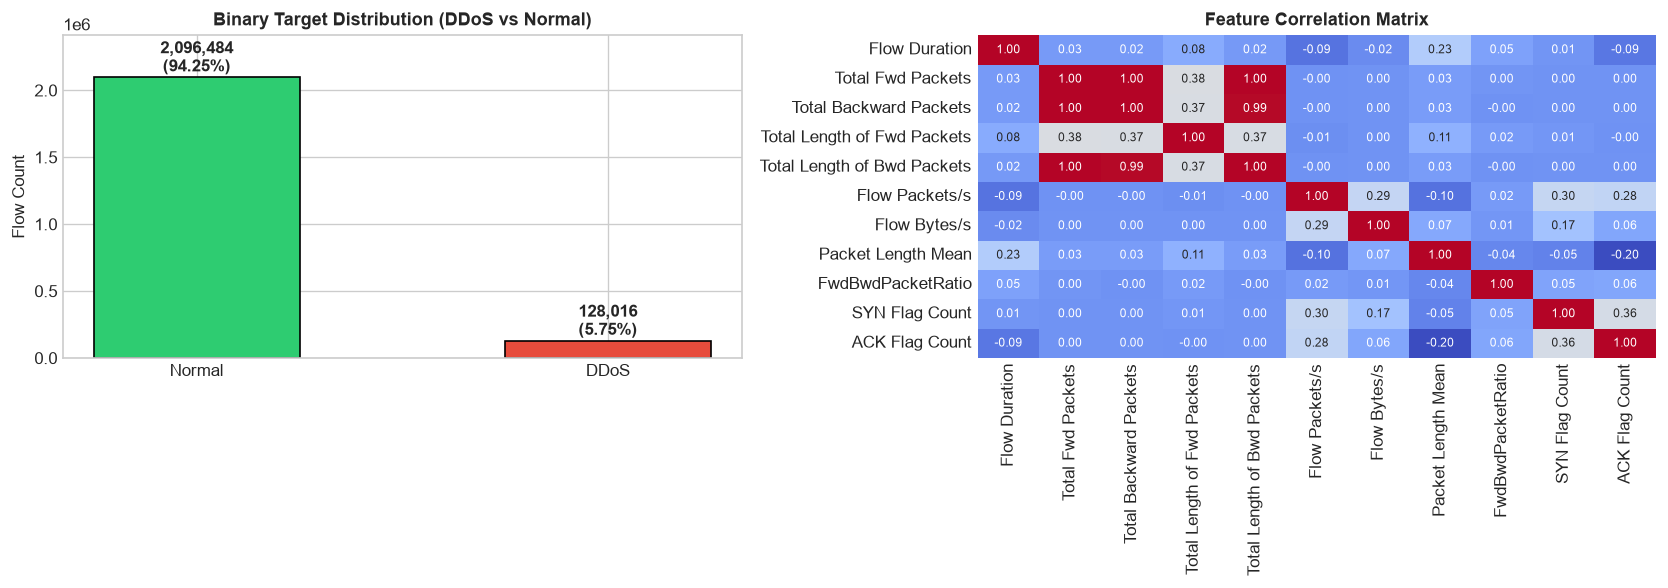

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Target Class Distribution
class_counts = df['TrafficClass'].value_counts()
colors = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', width=0.5)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 10000, f"{yval:,}\n({(yval/len(df))*100:.2f}%)", ha='center', va='bottom', fontweight='bold')
axes[0].set_title("Binary Target Distribution (DDoS vs Normal)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Flow Count")
axes[0].set_ylim(0, max(class_counts.values) * 1.15)

# Plot 2: Correlation Heatmap of Selected High-Variance Flow Features
corr_feats = [
    'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
    'Total Length of Fwd Packets', 'Total Length of Bwd Packets',
    'Flow Packets/s', 'Flow Bytes/s', 'Packet Length Mean',
    'FwdBwdPacketRatio', 'SYN Flag Count', 'ACK Flag Count'
]
corr_matrix = df[corr_feats].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1], cbar=False, annot_kws={'size': 7})
axes[1].set_title("Feature Correlation Matrix", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 11. Train / Test Split Preparation & Imbalance Analysis
Because timestamps are not provided in `MachineLearningCSV`, we establish a **deterministic stratified 70/30 train/test split (`random_state=42`)** as the documented standard.

In [11]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.30,
    random_state=42,
    stratify=df['BinaryLabel'].values
)

train_df = df.iloc[train_idx]
test_df = df.iloc[test_idx]

train_ddos = (train_df['BinaryLabel'] == 1).sum()
train_normal = (train_df['BinaryLabel'] == 0).sum()
test_ddos = (test_df['BinaryLabel'] == 1).sum()
test_normal = (test_df['BinaryLabel'] == 0).sum()

print("--- Stratified 70/30 Split Overview ---")
print(f"Training Partition (70%): {len(train_df):,} flows")
print(f" - DDoS:   {train_ddos:,} ({(train_ddos/len(train_df))*100:.2f}%)")
print(f" - Normal: {train_normal:,} ({(train_normal/len(train_df))*100:.2f}%)")

print(f"\nTesting Partition (30%):  {len(test_df):,} flows")
print(f" - DDoS:   {test_ddos:,} ({(test_ddos/len(test_df))*100:.2f}%)")
print(f" - Normal: {test_normal:,} ({(test_normal/len(test_df))*100:.2f}%)")

imbalance_ratio = train_normal / train_ddos
print(f"\nClass Imbalance Ratio (Normal : DDoS): {imbalance_ratio:.2f} : 1")
print("""[RECOMMENDED MODELING STRATEGY]
In the upcoming Random Forest phase:
1. Apply `class_weight='balanced'` in RandomForestClassifier to penalize false negatives on DDoS.
2. Alternatively, perform controlled benign downsampling on the TRAINING partition only (e.g. 3:1 Normal-to-DDoS ratio).
3. The TEST partition must remain strictly unaltered at original class proportions.""")

--- Stratified 70/30 Split Overview ---
Training Partition (70%): 1,557,150 flows
 - DDoS:   89,611 (5.75%)
 - Normal: 1,467,539 (94.25%)

Testing Partition (30%):  667,350 flows
 - DDoS:   38,405 (5.75%)
 - Normal: 628,945 (94.25%)

Class Imbalance Ratio (Normal : DDoS): 16.38 : 1
[RECOMMENDED MODELING STRATEGY]
In the upcoming Random Forest phase:
1. Apply `class_weight='balanced'` in RandomForestClassifier to penalize false negatives on DDoS.
2. Alternatively, perform controlled benign downsampling on the TRAINING partition only (e.g. 3:1 Normal-to-DDoS ratio).
3. The TEST partition must remain strictly unaltered at original class proportions.


### 12. Candidate Feature Selection (`DDOS_FEATURE_COLUMNS`) & Quality Report
Extract all numerical features suitable for Random Forest and compile `ddos_feature_report.csv`.

In [12]:
non_feature_cols = ['Label', 'TrafficClass', 'BinaryLabel']
DDOS_FEATURE_COLUMNS = [c for c in df.select_dtypes(include=[np.number]).columns if c not in non_feature_cols]

print(f"Total Candidate DDOS_FEATURE_COLUMNS: {len(DDOS_FEATURE_COLUMNS)}")

def categorize_feature(name):
    n = name.lower()
    if 'flag' in n:
        return 'TCP Flags'
    elif 'rate' in n or '/s' in n:
        return 'Flow Rate'
    elif 'iat' in n or 'active' in n or 'idle' in n or 'duration' in n:
        return 'Timing'
    elif 'packet' in n or 'pkt' in n or 'seg' in n:
        return 'Packet Behavior'
    elif 'byte' in n or 'length' in n or 'size' in n or 'win' in n:
        return 'Byte Behavior'
    elif 'subflow' in n:
        return 'Subflow Behavior'
    elif 'port' in n:
        return 'Port / Endpoint'
    else:
        return 'Flow Volume'

feat_report_records = []
for col in DDOS_FEATURE_COLUMNS:
    s = df[col]
    feat_report_records.append({
        'Feature': col,
        'DataType': str(s.dtype),
        'MissingCount': int(s.isnull().sum()),
        'MissingPercentage': float((s.isnull().sum() / len(df)) * 100),
        'InfiniteCount': int(np.isinf(s.values).sum()),
        'Min': float(s.min()),
        'Max': float(s.max()),
        'Mean': float(s.mean()),
        'Median': float(s.median()),
        'FeatureCategory': categorize_feature(col)
    })

feature_report_df = pd.DataFrame(feat_report_records)
feature_report_path = out_dir / 'ddos_feature_report.csv'
feature_report_df.to_csv(feature_report_path, index=False)
print(f"Saved Feature Quality Report: {feature_report_path.name}")
display(feature_report_df.head(10))

Total Candidate DDOS_FEATURE_COLUMNS: 74


Saved Feature Quality Report: ddos_feature_report.csv


,Feature,DataType,MissingCount,MissingPercentage,InfiniteCount,Min,Max,Mean,Median,FeatureCategory
0,Destination Port,int64,0,0.0000,0,0.0000,65535.0000,9499.4532,80.0000,Port / Endpoint
1,Flow Duration,int64,0,0.0000,0,-13.0000,119999998.0000,12428476.6321,48426.0000,Timing
2,Total Fwd Packets,int64,0,0.0000,0,1.0000,219759.0000,10.9722,2.0000,Packet Behavior
3,Total Backward Packets,int64,0,0.0000,0,0.0000,291922.0000,12.5121,2.0000,Packet Behavior
4,Total Length of Fwd Packets,int64,0,0.0000,0,0.0000,12900000.0000,645.9681,64.0000,Packet Behavior
5,Total Length of Bwd Packets,int64,0,0.0000,0,0.0000,655453030.0000,19678.8031,150.0000,Packet Behavior
6,Fwd Packet Length Max,int64,0,0.0000,0,0.0000,24820.0000,234.3795,39.0000,Packet Behavior
7,Fwd Packet Length Min,int64,0,0.0000,0,0.0000,2325.0000,21.5998,6.0000,Packet Behavior
8,Fwd Packet Length Mean,float64,0,0.0000,0,0.0000,4672.0000,66.4157,36.0000,Packet Behavior
9,Fwd Packet Length Std,float64,0,0.0000,0,0.0000,7125.5968,76.4585,0.0000,Packet Behavior


### 13. Save Output Datasets & Split Summaries
Export prepared binary dataset, model-ready numerical feature dataset, and split summary.

In [13]:
# 1. Full Prepared Binary Dataset (Metadata + Labels + Engineered Features)
full_binary_path = out_dir / 'ddos_binary_dataset.csv'
df.to_csv(full_binary_path, index=False)
full_size_mb = full_binary_path.stat().st_size / (1024 * 1024)
print(f"1. Saved Full Binary Dataset:  {full_binary_path.name} ({full_size_mb:.2f} MB, {len(df):,} rows)")

# 2. Model-Ready Numerical Dataset (DDOS_FEATURE_COLUMNS + BinaryLabel ONLY)
model_df = df[DDOS_FEATURE_COLUMNS].copy()
model_df['BinaryLabel'] = df['BinaryLabel'].values

model_features_path = out_dir / 'ddos_model_features.csv'
model_df.to_csv(model_features_path, index=False)
model_size_mb = model_features_path.stat().st_size / (1024 * 1024)
print(f"2. Saved Model-Ready Dataset:  {model_features_path.name} ({model_size_mb:.2f} MB, {len(model_df):,} rows)")

# 3. Save Split Summary
split_summary_data = [
    {"Metric": "train_rows", "Value": len(train_df)},
    {"Metric": "test_rows", "Value": len(test_df)},
    {"Metric": "train_ddos", "Value": int(train_ddos)},
    {"Metric": "train_normal", "Value": int(train_normal)},
    {"Metric": "test_ddos", "Value": int(test_ddos)},
    {"Metric": "test_normal", "Value": int(test_normal)},
    {"Metric": "train_start", "Value": "N/A (No Timestamps in MachineLearningCSV)"},
    {"Metric": "train_end", "Value": "N/A (No Timestamps in MachineLearningCSV)"},
    {"Metric": "test_start", "Value": "N/A (No Timestamps in MachineLearningCSV)"},
    {"Metric": "test_end", "Value": "N/A (No Timestamps in MachineLearningCSV)"},
    {"Metric": "split_method", "Value": "Stratified 70/30 Split (random_state=42)"}
]
split_summary_df = pd.DataFrame(split_summary_data)
split_summary_path = out_dir / 'ddos_split_summary.csv'
split_summary_df.to_csv(split_summary_path, index=False)
print(f"3. Saved Split Summary:        {split_summary_path.name}")
display(split_summary_df)

1. Saved Full Binary Dataset:  ddos_binary_dataset.csv (796.86 MB, 2,224,500 rows)


2. Saved Model-Ready Dataset:  ddos_model_features.csv (767.65 MB, 2,224,500 rows)
3. Saved Split Summary:        ddos_split_summary.csv


,Metric,Value
0,train_rows,1557150
1,test_rows,667350
2,train_ddos,89611
3,train_normal,1467539
4,test_ddos,38405
5,test_normal,628945
6,train_start,N/A (No Timestamps in MachineLearningCSV)
7,train_end,N/A (No Timestamps in MachineLearningCSV)
8,test_start,N/A (No Timestamps in MachineLearningCSV)
9,test_end,N/A (No Timestamps in MachineLearningCSV)


### 14. Final Quality Validation & Integrity Assertions
Validate assertions to ensure zero data corruption, zero label leakage, and raw file preservation.

In [14]:
# Assertions
assert raw_path.exists(), "Source cleaned dataset missing."
assert raw_size_mb > 800.0, "Source cleaned dataset was corrupted or truncated."

assert full_binary_path.exists(), "Binary dataset missing."
assert model_features_path.exists(), "Model features dataset missing."
assert feature_report_path.exists(), "Feature report missing."
assert split_summary_path.exists(), "Split summary missing."
assert coverage_summary_path.exists(), "Coverage summary missing."

assert set(df['BinaryLabel'].unique()) == {0, 1}, "Invalid BinaryLabel values."
assert set(df['TrafficClass'].unique()) == {'DDoS', 'Normal'}, "Invalid TrafficClass values."
assert 'BinaryLabel' not in DDOS_FEATURE_COLUMNS, "Label leakage in feature columns."
assert 'TrafficClass' not in DDOS_FEATURE_COLUMNS, "Label leakage in feature columns."
assert 'Label' not in DDOS_FEATURE_COLUMNS, "Label leakage in feature columns."

assert np.isinf(model_df[DDOS_FEATURE_COLUMNS].values).sum() == 0, "Infinities in model dataset."
assert model_df[DDOS_FEATURE_COLUMNS].isnull().sum().sum() == 0, "Nulls in model dataset."

print("==================================================")
print("DDoS DATASET PREPARATION COMPLETE")
print("==================================================")
print(f"Source Dataset Rows:         {total_raw_rows:,}")
print(f"Selected Primary Rows:       {len(df):,}")
print(f" - DDoS Flows:                {n_ddos:,} (5.75%)")
print(f" - Normal Flows:              {n_normal:,} (94.25%)")
print(f"Candidate Features Count:    {len(DDOS_FEATURE_COLUMNS)}")
print(f"Training Rows (70%):         {len(train_df):,}")
print(f"Testing Rows (30%):          {len(test_df):,}")
print(f"Class Imbalance (Normal:DDoS): {imbalance_ratio:.2f} : 1\n")

print("Generated Output Files:")
print(f" 1. {full_binary_path.relative_to(project_root)} ({full_size_mb:.2f} MB)")
print(f" 2. {model_features_path.relative_to(project_root)} ({model_size_mb:.2f} MB)")
print(f" 3. {feature_report_path.relative_to(project_root)}")
print(f" 4. {split_summary_path.relative_to(project_root)}")
print(f" 5. {coverage_summary_path.relative_to(project_root)}")
print("\n✅ All quality and integrity checks passed. Source dataset untouched.")

DDoS DATASET PREPARATION COMPLETE
Source Dataset Rows:         2,522,362
Selected Primary Rows:       2,224,500
 - DDoS Flows:                128,016 (5.75%)
 - Normal Flows:              2,096,484 (94.25%)
Candidate Features Count:    74
Training Rows (70%):         1,557,150
Testing Rows (30%):          667,350
Class Imbalance (Normal:DDoS): 16.38 : 1

Generated Output Files:
 1. data\processed\CIC_IDS2017\ddos_binary_dataset.csv (796.86 MB)
 2. data\processed\CIC_IDS2017\ddos_model_features.csv (767.65 MB)
 3. data\processed\CIC_IDS2017\ddos_feature_report.csv
 4. data\processed\CIC_IDS2017\ddos_split_summary.csv
 5. data\processed\CIC_IDS2017\ddos_coverage_summary.csv

✅ All quality and integrity checks passed. Source dataset untouched.
